# 03 · Matching to a reference

*Putting every station next to an independent estimate of the same temperature.*

Notebook 01 left us with a clean table of what about 160 thermometers reported every hour. It can't tell us whether any of them is *right*. Say a new sensor was fitted last spring and it has read 1.5 °C too warm ever since. The numbers it produces look exactly like weather. To catch it we need a second opinion, something independent that estimates the same temperature at the same place and hour. Then we can watch the difference between the two.

The second opinion here is **HRRR** (the High-Resolution Rapid Refresh). It's a weather model that NOAA runs every hour for the continental US on a grid of 3 km boxes. This notebook explains what a weather model's output actually is and opens one of its files by hand. Then it shows how four years of it were fetched for every station, corrects for height and looks at the difference *station minus model*. By the end we'll know what a normal difference looks like and which stations disagree with the model and why. We'll also meet the first real broken sensors of the project.

## Why subtracting a model works

Weather is the big and fast part of a temperature record. A cold front can drop the temperature 10 °C in an afternoon. A faulty sensor is the small and slow part, a fraction of a degree that never goes away. In the raw record the small part is buried under the big one.

A weather model sees the same front. Subtract the model from the station and the front shows up in both and mostly cancels. What's left is mostly two things. One is the station's own error. The other is **representativeness error**, the honest disagreement between a measurement at one point (a thermometer on an airfield) and an average over a 3 km box that may contain hills or a bay or a town. Representativeness error is real and often large but it's mostly *steady*. An airfield on the shore of a bay is always a bit warmer than a box that's half water. A sensor fault usually *changes* the difference. It starts on a date or grows over months or freezes. So the thing to watch isn't the difference itself but how the difference changes over time.

> **In ML terms.** Subtracting the model is like analysing a strong baseline's residuals. The baseline explains the shared and predictable variation and the anomalies in the residuals are what you investigate. It's also reconciliation like in payments. You don't check each payment. You check the difference between two ledgers and explain every change in it.

## Where a model's numbers come from

A weather model is a program that steps the atmosphere forward in time using the equations of fluid flow and heat. To start it needs a picture of the atmosphere *now*. That picture is built by **data assimilation**. The model takes its own previous short forecast (the **background** or first guess) and nudges it toward the latest observations from stations, balloons, aircraft, radar and satellites. It trusts each one according to how reliable it is. The result is the **analysis**, the model's best estimate of the current state, and the run steps forward from it.

So every forecast carries three timestamps. The **initialization time** is when the run started. The **lead time** is how far ahead it looks. The **valid time** is initialization plus lead, the moment the forecast describes. HRRR starts a new run every hour.

**Why we use the 1-hour forecast and not the analysis.** HRRR's analysis is built partly from airport reports including the very stations we want to check. Comparing a station with an analysis that's already been pulled toward that station would hide the station's errors. So for each hour we use the forecast that started one hour *earlier* (lead time 1 hour) which hadn't seen that hour's report yet. That's not perfect independence. The run's starting point was shaped by the previous hour's reports so a station that's wrong for months will have nudged the model a little toward itself. It's still much better than the analysis and the leftover dependence is worth remembering.

**Why 2021 onward.** HRRR has been upgraded several times and version 4 became operational in December 2020. An upgrade can change the model's typical values everywhere at once which would look like a step fault at every station on the same day. The *Learning WeatherBench 2* guide described the same problem for global models. Archived operational analyses mix many versions of a system and that's why reanalyses like ERA5 exist. HRRR has no reanalysis so we stay within one version.

> **In ML terms.** Using the analysis would be label leakage because the input already contains the target. The 1-hour forecast is the "only use features available before prediction time" rule.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from wxlab import stations as st, reference as ref

YEARS = range(2021, 2025)
REF_DIR = Path(DATA_DIR) / "reference"
CACHE_DIR = Path(DATA_DIR) / "hrrr_cache"

## Step 1 · One HRRR file opened by hand

HRRR's output lives on AWS in the bucket `noaa-hrrr-bdp-pds` with one file per run and lead time in **GRIB2** format. GRIB (GRIdded Binary) is the format weather centres have exchanged model output in for decades. A GRIB2 file is a stack of independent **messages**. Each one holds a single two-dimensional field (one variable at one level) compressed and with a header that says what it is.

The **Herbie** library knows where HRRR files live and how to read them. Below it finds the 1-hour forecast valid at 21:00 UTC on 1 July 2023 (the run started at 20:00) and lists what's inside.

In [3]:
import requests
from herbie import Herbie

H = Herbie("2023-07-01 20:00", model="hrrr", product="sfc", fxx=1, save_dir=CACHE_DIR, verbose=False)
inventory = H.inventory()
size_mb = int(requests.head(H.grib).headers["Content-Length"]) / 1e6
print("file:", H.grib)
print(f"{size_mb:.0f} MB, {len(inventory)} messages")
wanted = inventory[inventory.search_this.str.contains(":(?:TMP|DPT):2 m above ground")]
wanted[["grib_message", "start_byte", "end_byte", "variable", "level", "reference_time", "valid_time"]]

file: https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr.20230701/conus/hrrr.t20z.wrfsfcf01.grib2
161 MB, 170 messages


,grib_message,start_byte,end_byte,variable,level,reference_time,valid_time
70,71,44392769,45668572.0,TMP,2 m above ground,2023-07-01 20:00:00,2023-07-01 21:00:00
73,74,48525002,49752041.0,DPT,2 m above ground,2023-07-01 20:00:00,2023-07-01 21:00:00


One hour's surface file is about 160 MB and holds 170 fields covering temperatures, winds, clouds, radar reflectivity and much more. We need two of them. Those are the temperature and the dew point 2 metres above the ground at about 1.3 MB each.

Next to every GRIB2 file NOAA publishes a small **index file** (`.idx`) that lists the byte where each message starts. Asking AWS for just those bytes uses an ordinary HTTP feature called a **range request**. So each hour costs about 2.5 MB of download instead of 160 MB. Over four years of hours that's roughly 90 GB instead of 5.6 TB.

Notice the two time columns. `reference_time` is 20:00 when the run started and `valid_time` is 21:00, the hour it describes. These are the initialization time and the valid time from above written into the index.

> **In ML terms.** The index file plus range requests is the trick that makes cloud-native formats like Zarr and Parquet fast. Never read a whole object when you need a slice of it.

In [4]:
ds = H.xarray(":TMP:2 m above ground", remove_grib=True)
attrs = ds.t2m.attrs
print("grid:", attrs["GRIB_gridType"], f"{attrs['GRIB_Nx']} x {attrs['GRIB_Ny']} points,",
      f"{attrs['GRIB_DxInMetres'] / 1000:.0f} km spacing; units in the file: {attrs['GRIB_units']}")
print(f"longitudes in the file run from {float(ds.longitude.min()):.1f} to {float(ds.longitude.max()):.1f}")

grid: lambert 1799 x 1059 points, 3 km spacing; units in the file: K
longitudes in the file run from 225.9 to 299.1


Three details in that output are classic traps.

**Units.** The file stores kelvin and 0 °C is 273.15 K. Forget the conversion and temperatures come out near 300.

**Longitudes run from 0 to 360** and not from −180 to 180. California sits around 235–246 °E rather than 114–125 °W. Mixing the two conventions silently matches stations to points on the other side of the planet.

**The grid isn't latitude–longitude.** It's a **Lambert conformal** projection, a map made by laying a cone over North America that keeps shapes nearly right across the mid-latitudes. Grid rows aren't lines of constant latitude so you can't find a station's grid box by arithmetic. Each of the 1,799 × 1,059 points carries its own latitude and longitude. Finding the points nearest a station is a search and we do it with a **ball tree**, a spatial index over all 1.9 million points that's built once.

Here's the field over California with the stations on top.

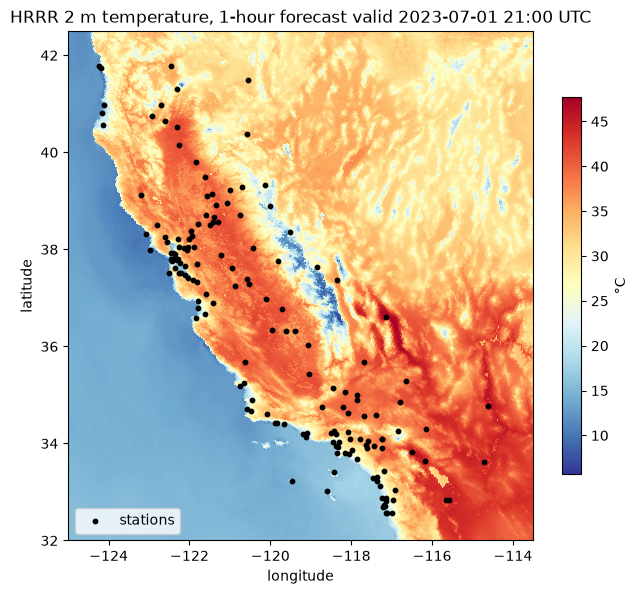

In [5]:
points = pd.read_parquet(REF_DIR / "station_points.parquet")
inside = ((ds.longitude > 360 - 125) & (ds.longitude < 360 - 113.5) & (ds.latitude > 32) & (ds.latitude < 42.5)).values
rows, cols = np.where(inside.any(axis=1))[0], np.where(inside.any(axis=0))[0]
ca = ds.isel(y=slice(rows.min(), rows.max() + 1), x=slice(cols.min(), cols.max() + 1))   # a rectangle of grid rows and columns
fig, ax = plt.subplots(figsize=(7.5, 7))
im = ax.pcolormesh(ca.longitude - 360, ca.latitude, ca.t2m - 273.15, cmap="RdYlBu_r", shading="auto")
ax.scatter(points.longitude, points.latitude, s=10, c="k", label="stations")
ax.set(xlim=(-125, -113.5), ylim=(32, 42.5), xlabel="longitude", ylabel="latitude",
       title="HRRR 2 m temperature, 1-hour forecast valid 2023-07-01 21:00 UTC")
plt.colorbar(im, label="°C", shrink=0.7); ax.legend(loc="lower left"); ax.set_aspect(1.2)
plt.show()

It's a July afternoon. It's over 40 °C in the Central Valley and the deserts, cool along the coast and cold on the Sierra Nevada. The coast is the interesting part for us. A cool band a few grid boxes wide hugs the shoreline and a station a few kilometres inland can sit on the other side of a very sharp boundary.

## Step 2 · Fetching four years for every station

The project needs this for every hour of 2021–2024 (35,064 hours) at every station. The fetching code is in `wxlab.reference`. Here's what it does because each choice is an ingestion lesson.

- **Only what's needed.** For each hour it downloads the index and then the two byte ranges. It never downloads the whole file.
- **Sample and then discard.** Each field is sampled at the stations and the grid is thrown away. The value at a station is an **inverse-distance-weighted** average of the 4 nearest grid points where nearer points count more. A California crop of every field is also kept (about 14 GB) for the gridded-data notebook later.
- **One connection per worker.** The first version opened several new HTTPS connections for every file. At thousands of files something between this machine and AWS started refusing new connections and over a thousand fetches failed. Reusing one long-lived connection per worker (HTTP keep-alive) got rid of the failures and made each fetch about ten times faster.
- **Idempotent units saved as they finish.** Each successful hour is saved right away and each finished day becomes one Parquet file. So a crash or a network drop costs only the hours it hit and rerunning fetches only what's missing. Hours that still fail after several passes are recorded as empty rows so a gap in the reference is visible rather than silent.

In [6]:
reference = ref.load(REF_DIR / "hrrr")
reference = reference[reference.time.dt.year.isin(YEARS)]
hours = reference.time.nunique()
empty = reference.groupby("time").hrrr_air_temperature.apply(lambda s: s.isna().all()).sum()
print(f"{len(reference):,} rows: {reference.station_id.nunique()} stations x {hours:,} hours")
print(f"hours with no HRRR value (fetch failed or file missing on AWS): {empty}")
day_files = list((REF_DIR / "hrrr").rglob("*.parquet"))
print(f"{len(day_files)} day files, {sum(f.stat().st_size for f in day_files) / 1e6:.0f} MB in total")

5,785,560 rows: 165 stations x 35,064 hours
hours with no HRRR value (fetch failed or file missing on AWS): 0
1461 day files, 118 MB in total


## Step 3 · Correcting for height

A grid box's terrain height is an average over 3 km and a station can sit above or below it. Air usually cools by about 6.5 °C per kilometre of height (the standard **lapse rate**). So before comparing we shift the model's temperature to the station's height with `t_corrected = t_hrrr − 0.0065 × (station height − model height)`. The model's terrain height at each station comes from HRRR's surface height field.

In [7]:
model_elev = pd.read_parquet(REF_DIR / "hrrr_model_elevation.parquet").set_index("station_id").model_elevation_m
history = st.load_station_history(Path(DATA_DIR) / "meta").set_index("station_id")
dz = (points.set_index("station_id").elevation_m - model_elev).rename("dz").to_frame()
dz["name"] = history["name"]
print(f"station minus model height: median {dz.dz.abs().median():.0f} m; above 100 m at {(dz.dz.abs() > 100).sum()} stations")
dz.reindex(dz.dz.abs().sort_values(ascending=False).index).head(5).round(0)

station minus model height: median 6 m; above 100 m at 7 stations


,dz,name
station_id,,
72289093136,410.0,MOUNT WILSON
72292023191,251.0,CATALINA AIRPORT
99999953150,227.0,YOSEMITE VILLAGE 12 W
72065200433,-202.0,BRIDGEPORT SONORA JUNCTION
72383023187,182.0,SANDBERG


For most stations the height difference is small (tens of metres) so the correction is a fraction of a degree. A few stations differ by hundreds of metres. They're places on a ridge or a hilltop above the model's smoothed terrain. Keep Catalina in mind. It's an airport on top of a mountain on an island and we'll see that the correction makes it *worse*.

## Step 4 · The matched table

Now we join stations and HRRR by station and hour. For every station-hour the result has the station's value, the height-corrected HRRR value and the difference.

5,099,804 matched station-hours at 159 stations
difference station - HRRR: mean (bias) +0.15 °C, RMSE 1.79 °C, median absolute 0.89 °C


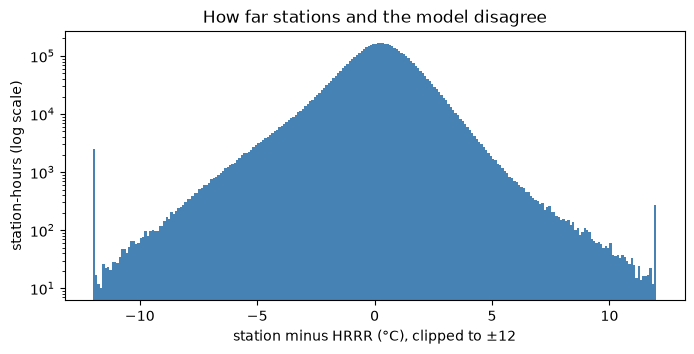

In [8]:
hourly = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", years=YEARS)
matched = ref.match(hourly, reference, model_elev)
matched = matched.dropna(subset=["air_temperature", "hrrr_air_temperature"])
networks = st.station_networks(hourly)
matched = matched.join(networks, on="station_id")
d = matched.diff_air_temperature
print(f"{len(matched):,} matched station-hours at {matched.station_id.nunique()} stations")
print(f"difference station - HRRR: mean (bias) {d.mean():+.2f} °C, RMSE {np.sqrt((d ** 2).mean()):.2f} °C, "
      f"median absolute {d.abs().median():.2f} °C")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(d.clip(-12, 12), bins=240, color="steelblue")
ax.set(yscale="log", xlabel="station minus HRRR (°C), clipped to ±12", ylabel="station-hours (log scale)",
       title="How far stations and the model disagree")
plt.show()

Two scores from the WeatherBench 2 guide sum up the comparison. **Bias** is the average difference and tells us whether stations are systematically warmer or colder than the model. **RMSE** (root mean squared error) is the typical size of the difference with large misses counting extra. Here the bias is a fraction of a degree and the RMSE is under 2 °C. For most hours the model and the thermometer agree to within a couple of degrees.

The histogram on a log scale shows the shape. Most hours sit in a narrow peak around zero. The tails are long though and a small number of hours disagree by 10 °C or more. Some of those are the model getting a sharp local event wrong and some are the station being wrong. Telling the two apart is what the checks in notebook 05 are for.

> **In ML terms.** The difference is a residual and its distribution is heavy-tailed. That matters because a training loss or a QA threshold that assumes normal errors will either be dominated by those tails or blind to them.

## Step 5 · Station by station

Here are the same two numbers per station. The **mean difference** is a steady offset. The **spread of the difference** is its standard deviation, or how much it wanders. A healthy station with a steady representativeness error has a non-zero mean and a small spread.

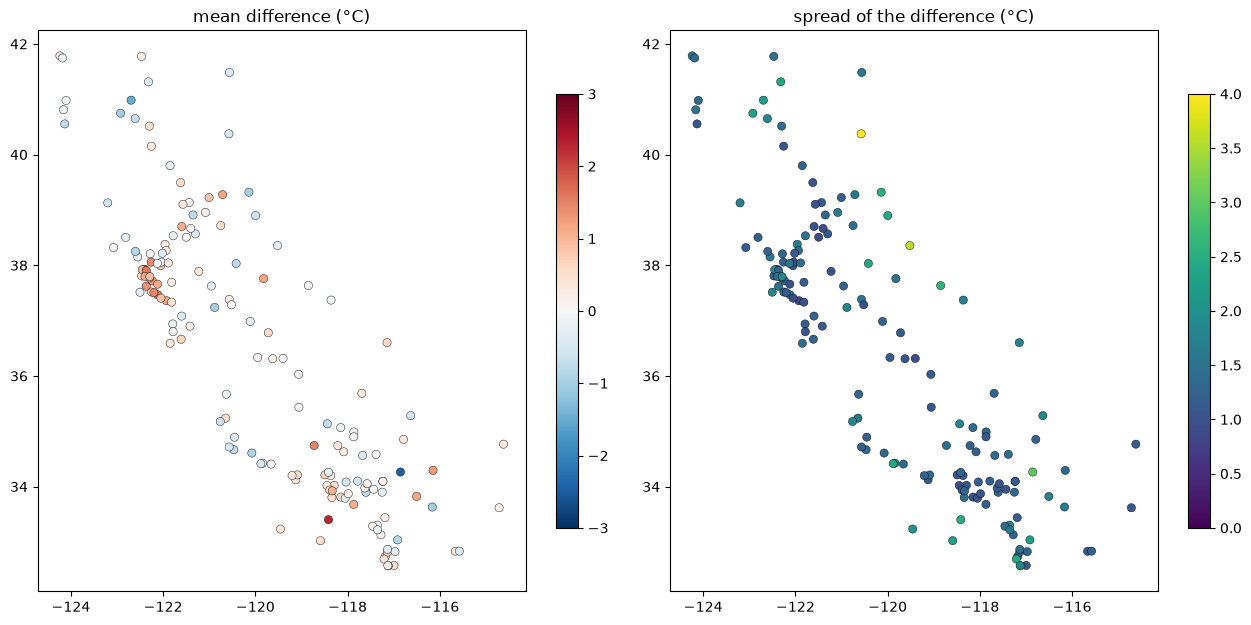

mean difference by network (°C):
                   count  mean   25%   50%   75%
network                                         
airport            132.0  0.08 -0.29  0.13  0.42
climate reference    7.0 -0.04 -0.59 -0.11  0.42
coastal             19.0  0.53 -0.10  0.48  1.10


In [9]:
per_station = (matched.groupby("station_id").diff_air_temperature.agg(["mean", "std", "count"])
               .join(networks).join(history["name"]))
per_station = per_station[per_station["count"] > 24 * 180]               # at least half a year of hours
pts = points.set_index("station_id").loc[per_station.index]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, col, cmap, lim, title in [(axes[0], "mean", "RdBu_r", 3, "mean difference (°C)"),
                                  (axes[1], "std", "viridis", 4, "spread of the difference (°C)")]:
    sc = ax.scatter(pts.longitude, pts.latitude, c=per_station[col].clip(-lim, lim) if col == "mean" else per_station[col].clip(0, lim),
                    cmap=cmap, vmin=-lim if col == "mean" else 0, vmax=lim, s=35, edgecolor="k", linewidth=0.3)
    plt.colorbar(sc, ax=ax, shrink=0.7); ax.set_title(title); ax.set_aspect(1.2)
plt.tight_layout(); plt.show()
print("mean difference by network (°C):")
print(per_station.groupby("network")["mean"].describe()[["count", "mean", "25%", "50%", "75%"]].round(2))

Three patterns stand out and each one has a physical explanation behind it rather than a faulty sensor.

**The bay and the coast run warm.** Stations around San Francisco Bay and on the coast are warmer than the model on average and the warmest by about 1.5 °C. Their 3 km grid box is partly water and the model's water-cooled box is colder than the shoreline airfield. This is representativeness error in its purest form. Both numbers are right about different things.

**Mountain valleys run cold or wander.** Stations in mountain valleys like Big Bear and Trinity Center are colder than the model on average. High-valley stations like Bridgeport, Mammoth and Big Bear have the largest spread. On clear calm nights cold air drains downhill and pools in valley floors which makes them far colder than the slopes around them. A 3 km grid box averages the valley with its slopes and misses the pool.

**The climate reference stations sit close to zero on average.** These are the research-grade sites placed away from buildings and asphalt. It's reassuring about both sources that these agree best with the model.

In [10]:
cols = ["name", "network", "mean", "std"]
print("Most negative mean difference:"); print(per_station.sort_values("mean").head(5)[cols].round(2).to_string())
print("\nMost positive mean difference:"); print(per_station.sort_values("mean").tail(5)[cols].round(2).to_string())
print("\nLargest spread:"); print(per_station.sort_values("std").tail(5)[cols].round(2).to_string())

Most negative mean difference:
                                              name  network  mean   std
station_id                                                             
A0685400115                  BIG BEAR CITY AIRPORT  airport -2.48  2.99
A0705300346                 TRINITY CENTER AIRPORT  airport -1.52  2.21
72290993115             NAVAL AUXILIARY LANDING FD  airport -1.37  8.09
72019300117  LONNIE POOL FIELD WEAVERVILLE AIRPORT  airport -1.05  2.33
74718703104               DESERT RESORTS RGNL ARPT  airport -1.03  1.64

Most positive mean difference:
                                                name  network  mean   std
station_id                                                               
72383023187                                 SANDBERG  airport  1.50  1.49
72493723289  PALO ALTO AIRPORT OF SANTA CLARA COUNTY  airport  1.53  1.84
99847799999                 RICHMOND (POINT POTRERO)  coastal  1.58  1.22
99403699999                                 RICHMOND  coastal  

**Catalina** is the case where the lapse rate fails. Its airport sits on a ridge about 480 m up on an island. The model's terrain there is about 225 m because it averages the island's ridges with the ocean around them. So the correction cools the model by about 1.6 °C to "lift" it up to the airport. But along the California coast the air usually *isn't* colder higher up. Cool and moist ocean air forms a shallow **marine layer** near the surface with warmer and drier air above it. That's a **temperature inversion**, the opposite of the standard lapse rate. The ridge top is often above the marine layer and warmer than the sea surface below. Applying the standard lapse rate there makes the disagreement bigger, not smaller. A correction based on an average atmosphere can be wrong exactly where the atmosphere isn't average. The next cell checks this with Catalina's own numbers.

In [11]:
cat = matched[matched.station_id == "72292023191"]
raw = (cat.air_temperature - cat.hrrr_air_temperature).mean()
print(f"Catalina: station {cat.elevation_m.iloc[0]:.0f} m, model terrain {cat.model_elevation_m.iloc[0]:.0f} m; "
      f"mean difference without correction {raw:+.2f} °C, with correction {cat.diff_air_temperature.mean():+.2f} °C")

Catalina: station 477 m, model terrain 226 m; mean difference without correction +0.66 °C, with correction +2.29 °C


## Step 6 · The difference through the day

If the difference were pure sensor error it wouldn't care what time it is. It does.

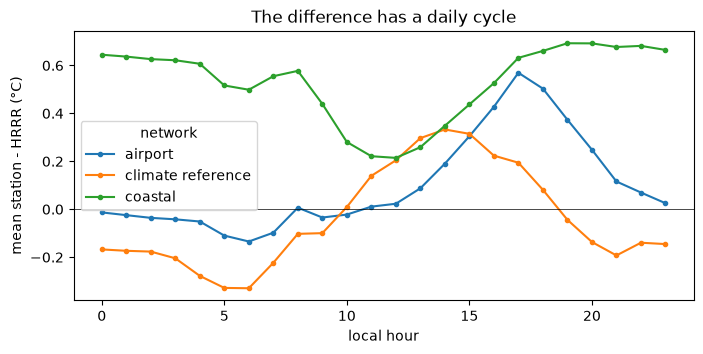

In [12]:
local_hour = matched.time.dt.tz_convert("America/Los_Angeles").dt.hour
cycle = matched.groupby([matched.network, local_hour]).diff_air_temperature.mean().unstack(0)
ax = cycle.plot(figsize=(8, 3.5), marker=".")
ax.axhline(0, color="k", lw=0.5)
ax.set(xlabel="local hour", ylabel="mean station - HRRR (°C)", title="The difference has a daily cycle")
plt.show()

Each network's difference moves through the day by about half a degree to 0.7 °C between its lowest and highest hour. Part of this is the model. Forecast models often struggle with the shallow night-time layer near the ground and with how fast the ground heats up after sunrise. Part is the stations. An airport surrounded by asphalt stays warm into the evening. And part is timing. The airport reading was taken several minutes before the hour and temperature changes fast during the morning warm-up.

For the checks this means the "normal" difference depends on the hour. A check that compares each hour with the station's usual difference *for that hour* will be sharper than one that uses a single average.

## Step 7 · What a broken sensor looks like

Everything so far has been honest disagreement. Here's the first real fault of the project at Susanville's airport station in September 2021.

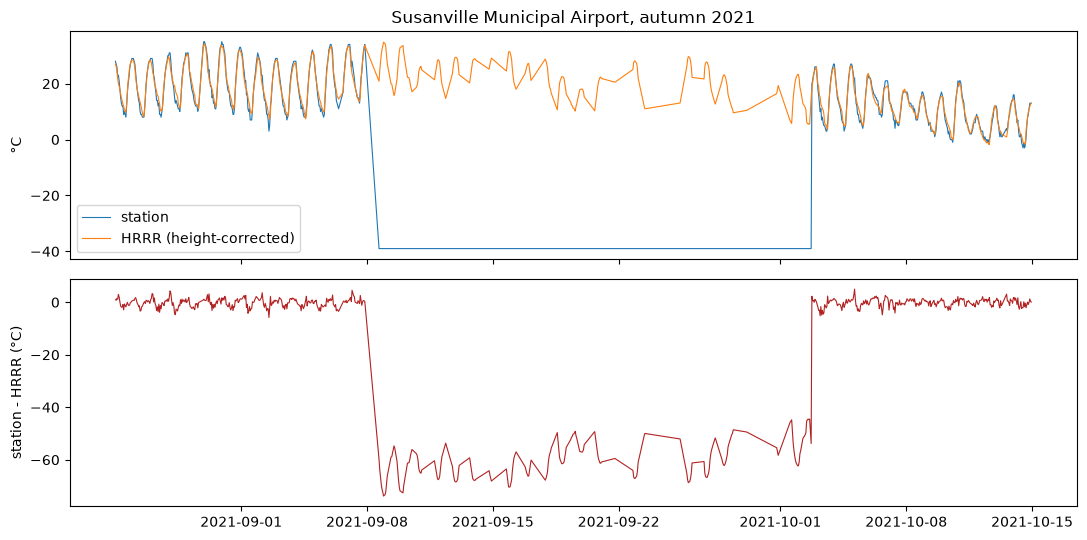

hours at or below -30 °C: 212; values: [np.float64(-39.0)]; NOAA quality codes on them: {'1': 207, '2': 5}


In [13]:
sus = matched[(matched.station_id == "72583799999") & (matched.time >= "2021-08-25") & (matched.time < "2021-10-15")]
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(sus.time, sus.air_temperature, lw=0.8, label="station")
axes[0].plot(sus.time, sus.hrrr_air_temperature_adj, lw=0.8, label="HRRR (height-corrected)")
axes[0].set_ylabel("°C"); axes[0].legend(); axes[0].set_title("Susanville Municipal Airport, autumn 2021")
axes[1].plot(sus.time, sus.diff_air_temperature, lw=0.8, color="firebrick")
axes[1].set_ylabel("station - HRRR (°C)")
plt.tight_layout(); plt.show()
stuck = sus[sus.air_temperature <= -30]
print(f"hours at or below -30 °C: {len(stuck)}; values: {sorted(stuck.air_temperature.unique())}; "
      f"NOAA quality codes on them: {stuck.tmp_quality.value_counts().to_dict()}")

In the middle of a California September the station reports around −39 °C for long stretches with a dew point of about −69 °C while the model says 20–35 °C. That's not weather. It's a sensor or its electronics failing and most likely reporting a fixed value close to the bottom of its range. NOAA's own checks marked a handful of these hours as suspect and passed almost all the rest (the counts are printed above).

It's not the only one. The Naval Auxiliary Landing Field at Imperial Beach sits on the coast just north of the Mexican border and it shows a different failure.

In [14]:
nal = matched[matched.station_id == "72290993115"]
month = nal.time.dt.tz_localize(None).dt.to_period("M")
cold = nal.air_temperature <= -15
by_month = pd.DataFrame({"hours at or below -15 °C": cold.groupby(month).sum(),
                         "mean difference (°C)": nal.groupby(month).diff_air_temperature.mean().round(1)})
print(by_month[by_month["hours at or below -15 °C"] > 0].to_string())
print(f"\nvalues: {nal.air_temperature[cold].value_counts().head(3).to_dict()}; "
      f"NOAA quality codes: {nal.tmp_quality[cold].value_counts().to_dict()}")

         hours at or below -15 °C  mean difference (°C)
time                                                   
2023-12                       187                  -8.7
2024-01                       319                 -17.3
2024-02                       277                 -15.6
2024-03                       314                 -16.7
2024-04                       237                 -12.9
2024-05                       293                 -15.4
2024-06                       131                  -9.3
2024-11                        60                  -4.3

values: {-16.7: 1799, -17.2: 14, -17.0: 4}; NOAA quality codes: {'5': 1522, '6': 293, '7': 2, '1': 1}


For seven months from December 2023 to June 2024 this coastal station kept reporting about −16.7 °C, which is exactly 2 °F, mixed in with normal readings. This is a place that basically never freezes. Then it recovered, relapsed briefly in November and recovered again. A value pinned to one number that repeats on and off is a classic sign of a failing sensor or a stuck default value in the station's software. NOAA's checks passed most of these hours.

On the raw temperature plot faults like these are obvious. Most faults aren't. The point of the difference series is that a 1 °C fault would stand out against a steady difference just as clearly as this one stands out against the weather. Notebooks 04 and 05 rely on that.

### A NOAA flag that may be wrong

Notebook 01 found that NOAA marks most of Moffett Federal Airfield's temperatures from 2020 onward as *erroneous*. If they really were the difference from HRRR should be large or erratic. Here's its monthly mean difference and spread next to the share of hours NOAA flagged.

In [15]:
mof = matched[matched.station_id == "74509023244"]
month = mof.time.dt.tz_localize(None).dt.to_period("M")
summary = pd.DataFrame({
    "mean difference": mof.groupby(month).diff_air_temperature.mean(),
    "spread": mof.groupby(month).diff_air_temperature.std(),
    "share flagged erroneous": mof.tmp_quality.isin(["3", "7"]).groupby(month).mean(),
})
print(summary.describe().loc[["mean", "min", "max"]].round(2))
bay = per_station[per_station.name.str.contains("SAN JOSE|PALO ALTO|SAN CARLOS|HAYWARD", na=False)][["name", "mean", "std"]]
print("\nnearby airports for comparison:"); print(bay.round(2).to_string())

      mean difference  spread  share flagged erroneous
mean             0.83    0.91                     0.91
min              0.54    0.73                     0.73
max              1.12    1.08                     1.00

nearby airports for comparison:
                                                name  mean   std
station_id                                                      
72493723289  PALO ALTO AIRPORT OF SANTA CLARA COUNTY  1.53  1.84
72493893231                       SAN CARLOS AIRPORT  0.53  1.37
72585093228                HAYWARD EXECUTIVE AIRPORT  1.15  1.00


Moffett's difference from the model is small and steady month after month and in line with nearby Bay Area airports. Meanwhile NOAA flags almost every hour as erroneous. The values look fine. Either NOAA's check is reacting to something other than the temperature itself (like a mismatch in the station's metadata) or it's just wrong for this station. A quality flag is a claim and claims can be tested. This one doesn't survive comparison with an independent source. Notebook 05 comes back to both stations.

## Step 8 · Dew point

In [16]:
dd = matched.diff_dew_point_temperature.dropna()
print(f"dew point, station - HRRR: bias {dd.mean():+.2f} °C, RMSE {np.sqrt((dd ** 2).mean()):.2f} °C, "
      f"spread {dd.std():.2f} °C (air temperature spread: {d.std():.2f} °C)")

dew point, station - HRRR: bias +0.26 °C, RMSE 2.24 °C, spread 2.23 °C (air temperature spread: 1.78 °C)


Dew point agrees less well than temperature and its spread is noticeably larger. Moisture is more local than heat (think of an irrigated field or a sea breeze or a shower) and it's harder for a model to place precisely. It's also not height-corrected because how moisture changes with height depends on the weather. Checks on dew point will need wider tolerances than checks on temperature.

## Step 9 · Is the difference steady?

The whole plan rests on the difference being steady for healthy stations. The final cell measures that directly. For each station it takes the standard deviation of the *monthly mean* difference over the four years. Day-to-day weather averages out within a month so a healthy station's monthly means should barely move.

In [17]:
month = matched.time.dt.tz_localize(None).dt.to_period("M")
monthly = matched.groupby(["station_id", month]).diff_air_temperature.mean().unstack()
steadiness = monthly.std(axis=1).rename("monthly spread").to_frame().join(history["name"]).join(networks)
print(f"median station: monthly means vary by {steadiness['monthly spread'].median():.2f} °C")
print(f"stations whose monthly mean wanders by more than 1 °C: {(steadiness['monthly spread'] > 1).sum()}")
steadiness.sort_values("monthly spread", ascending=False).head(8).round(2)

median station: monthly means vary by 0.38 °C
stations whose monthly mean wanders by more than 1 °C: 9


,monthly spread,name,network
station_id,,,
72290993115,5.42,NAVAL AUXILIARY LANDING FD,airport
72583799999,5.34,SUSANVILLE MUNI,airport
72292800369,1.93,MCOLF CAMP PENDLETON RED BEACH AIRPORT,airport
72292593117,1.18,NALF/F. SHERMAN FLD ARPT,airport
A0705300346,1.18,TRINITY CENTER AIRPORT,airport
72493723289,1.17,PALO ALTO AIRPORT OF SANTA CLARA COUNTY,airport
72065200433,1.17,BRIDGEPORT SONORA JUNCTION,airport
72292023191,1.07,CATALINA AIRPORT,airport


For the median station the monthly mean difference moves by only a few tenths of a degree over four years. That's the stable background that notebook 04 will plant faults into and notebook 05 will try to find them against. The stations at the top of this list are the first candidates for real problems. Some will turn out to be the representativeness stories above (seasonal marine layers and cold valleys) and some will be faults. Susanville and the naval airfield are at the very top.

## What surprised me

**The model and the thermometers mostly agree and the disagreements have geography.** The bias is a fraction of a degree overall. But bay and coastal stations run warm and high valleys run cold and each pattern has a physical reason: water in the grid box and cold air pooling at night.

**A standard correction can make things worse.** The lapse rate assumes air cools with height but over the marine layer it warms. Catalina's difference grows when it's "corrected".

**The difference has a daily cycle.** "Normal" depends on the hour so checks should compare like with like.

**Two real broken sensors and a NOAA flag that may be wrong.** Susanville reported −39 °C in September. A coastal naval airfield reported 2 °F on and off for seven months. NOAA passed most of those hours. Meanwhile Moffett looks healthy and NOAA marks nearly all its values erroneous.

**The ingestion lesson was about connections and not bandwidth.** Opening a new connection per request failed at scale. One reused connection per worker fixed it.

## Check yourself

<details><summary>Why use HRRR's 1-hour forecast rather than its analysis?</summary>
The analysis is pulled toward recent observations including the stations being checked so it would partly agree with a station's own errors. The forecast that started an hour earlier hasn't seen that hour's report.
</details>

<details><summary>A coastal station is 1.8 °C warmer than HRRR every month for four years. Is it faulty?</summary>
Probably not. A steady offset is what representativeness error looks like, for example a grid box that's partly water. What would be suspicious is a change in that offset.
</details>

<details><summary>Why can the lapse-rate correction make a coastal hilltop station look worse?</summary>
Along the coast the air near the surface is often a cool marine layer with warmer air above it (an inversion). The correction assumes the opposite so it cools the model when it should warm it.
</details>

<details><summary>What does a 2.5 MB download per hour instead of 160 MB depend on?</summary>
The index file that lists each message's byte position and HTTP range requests that fetch only those bytes.
</details>

New terms from this notebook are in [`docs/glossary.md`](../docs/glossary.md).